# Day 100 — Problems with the Perceptron

In this notebook we will demonstrate the main limitations of a single perceptron, and then the fixes:

1. Fails on **non-linearly separable** data (XOR, circles, moons)
2. **Brute-force proof** that XOR cannot be solved by one perceptron
3. **Never converges** on non-separable data (and the pocket workaround)
4. **No unique solution**: result depends on order and initialization (no margin)
5. **Sensitive to feature scaling**
6. **Hard outputs**: no probabilities
7. **Binary only**: needs one-vs-rest for several classes
8. **Fixes**: feature engineering, and multi-layer networks

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

np.random.seed(42)

## 0. Perceptron implementation (from Days 97-98)

In [2]:
class Perceptron:
    def __init__(self, n_features, lr=0.1):
        self.w = np.zeros(n_features); self.b = 0.0; self.lr = lr

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y, epochs=100, seed=0, w0=None, b0=0.0):
        rng = np.random.RandomState(seed)
        if w0 is not None: self.w = np.array(w0, dtype=float)
        self.b = b0
        self.mistakes_per_epoch = []
        self.total_updates = 0
        for _ in range(epochs):
            errors = 0
            for j in rng.permutation(len(X)):
                y_hat = int(X[j] @ self.w + self.b >= 0)
                if y_hat != y[j]:
                    self.w += self.lr * (y[j] - y_hat) * X[j]
                    self.b += self.lr * (y[j] - y_hat)
                    errors += 1; self.total_updates += 1
            self.mistakes_per_epoch.append(errors)
            if errors == 0:
                break
        return self

def plot_boundary(ax, model_predict, X, y, title):
    pad = 0.5
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    Z = model_predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title)

## 1. Where a single perceptron works, and where it fails

Four datasets: linearly separable, XOR, concentric circles, two moons.

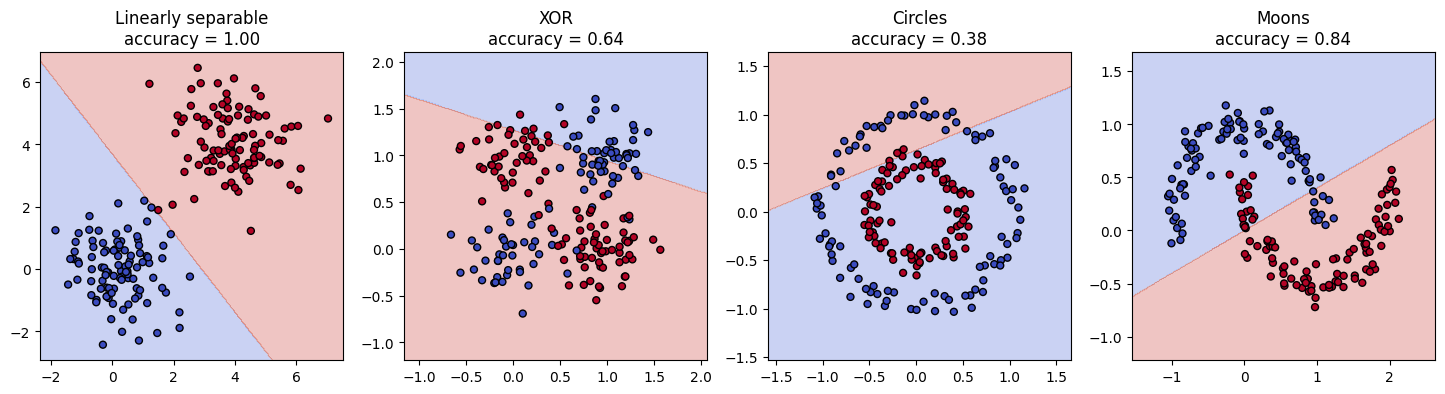

In [3]:
def make_xor(n=200, noise=0.25, seed=0):
    rng = np.random.RandomState(seed)
    X = rng.randint(0, 2, size=(n, 2)).astype(float)
    y = (X[:, 0].astype(int) ^ X[:, 1].astype(int))
    return X + rng.randn(n, 2) * noise, y

datasets = {
    "Linearly separable": make_blobs(n_samples=200, centers=[[0, 0], [4, 4]], cluster_std=1.0, random_state=1),
    "XOR": make_xor(),
    "Circles": make_circles(n_samples=200, noise=0.08, factor=0.5, random_state=1),
    "Moons": make_moons(n_samples=200, noise=0.1, random_state=1),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, (X_d, y_d)) in zip(axes, datasets.items()):
    p = Perceptron(2).fit(X_d, y_d, epochs=200)
    acc = (p.predict(X_d) == y_d).mean()
    plot_boundary(ax, p.predict, X_d, y_d, f"{name}\naccuracy = {acc:.2f}")
plt.show()

## 2. Proof by brute force: XOR cannot be solved by one perceptron

We try a large grid of `(w1, w2, b)` values on the four XOR points. If a single line could solve XOR, some combination would get 4/4.

Algebraic proof: we would need `b < 0`, `w1 + b ≥ 0`, `w2 + b ≥ 0`, and `w1 + w2 + b < 0`.
Adding the middle two gives `w1 + w2 + 2b ≥ 0`, so `w1 + w2 + b ≥ −b > 0`, contradicting the last condition.

In [4]:
pts = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}

grid = np.linspace(-3, 3, 61)
for name, target in gates.items():
    target = np.array(target)
    best = 0
    for w1 in grid:
        for w2 in grid:
            for b in grid:
                pred = (pts @ np.array([w1, w2]) + b >= 0).astype(int)
                best = max(best, (pred == target).mean())
    print(f"{name:3s}: best accuracy over {len(grid)**3:,} weight combinations = {best:.2f}")

AND: best accuracy over 226,981 weight combinations = 1.00
OR : best accuracy over 226,981 weight combinations = 1.00
XOR: best accuracy over 226,981 weight combinations = 0.75


## 3. Non-separable data: the perceptron never converges

Mistakes per epoch (first 25): [39, 43, 31, 40, 26, 41, 34, 32, 39, 33, 35, 33, 40, 32, 38, 39, 36, 28, 31, 37, 36, 40, 38, 34, 33]
Epochs run: 100 (never reached 0 mistakes)


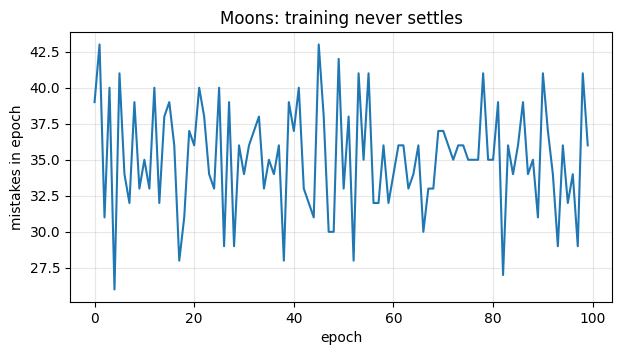

In [5]:
X_m, y_m = datasets["Moons"]
p_m = Perceptron(2).fit(X_m, y_m, epochs=100)
print("Mistakes per epoch (first 25):", p_m.mistakes_per_epoch[:25])
print("Epochs run:", len(p_m.mistakes_per_epoch), "(never reached 0 mistakes)")

plt.figure(figsize=(7, 3.5))
plt.plot(p_m.mistakes_per_epoch); plt.xlabel("epoch"); plt.ylabel("mistakes in epoch")
plt.title("Moons: training never settles"); plt.grid(alpha=0.3); plt.show()

In [6]:
# Pocket algorithm: remember the best weights seen so far
def pocket(X, y, lr=0.1, epochs=100, seed=0):
    rng = np.random.RandomState(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    best = (w.copy(), b, int((((X @ w + b) >= 0).astype(int) != y).sum()))
    for _ in range(epochs):
        for j in rng.permutation(len(X)):
            y_hat = int(X[j] @ w + b >= 0)
            if y_hat != y[j]:
                w = w + lr * (y[j] - y_hat) * X[j]; b = b + lr * (y[j] - y_hat)
                m = int((((X @ w + b) >= 0).astype(int) != y).sum())
                if m < best[2]:
                    best = (w.copy(), b, m)
    return best

w_pk, b_pk, m_pk = pocket(X_m, y_m)
print("Last-epoch mistakes of plain perceptron:", p_m.mistakes_per_epoch[-1], "of", len(X_m))
print("Pocket best mistakes                   :", m_pk, "of", len(X_m))
print("Even the best line cannot fix the problem: a straight boundary is the wrong shape for moons.")

Last-epoch mistakes of plain perceptron: 36 of 200
Pocket best mistakes                   : 23 of 200
Even the best line cannot fix the problem: a straight boundary is the wrong shape for moons.


## 4. No unique solution and no margin

On perfectly separable data, different data orders and initial weights give **different** valid boundaries. The perceptron stops at the first separating line, which may pass very close to some points.

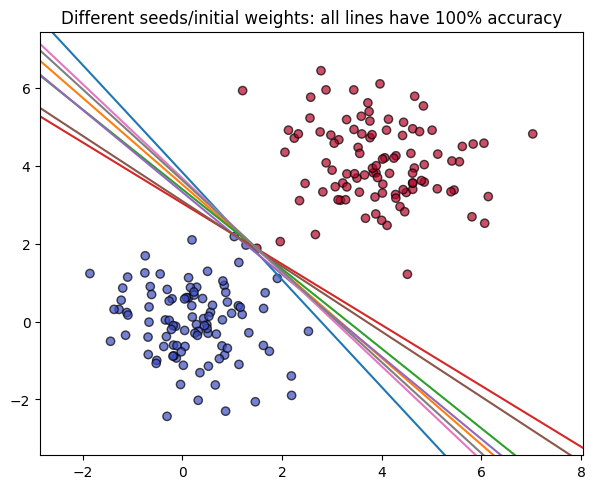

In [7]:
X_s, y_s = datasets["Linearly separable"]
xs = np.linspace(X_s[:, 0].min() - 1, X_s[:, 0].max() + 1, 100)

plt.figure(figsize=(7, 5.5))
plt.scatter(X_s[:, 0], X_s[:, 1], c=y_s, cmap="coolwarm", edgecolor="k", alpha=0.7)
rng = np.random.RandomState(0)
for seed in range(8):
    w0 = rng.randn(2) * 2
    p = Perceptron(2, lr=0.1).fit(X_s, y_s, epochs=500, seed=seed, w0=w0, b0=rng.randn())
    if abs(p.w[1]) > 1e-9 and (p.predict(X_s) == y_s).all():
        plt.plot(xs, -(p.w[0] * xs + p.b) / p.w[1], lw=1.5)
plt.ylim(X_s[:, 1].min() - 1, X_s[:, 1].max() + 1); plt.xlim(xs[0], xs[-1])
plt.title("Different seeds/initial weights: all lines have 100% accuracy"); plt.show()

In [8]:
def min_margin(p, X, y):
    t = 2 * y - 1
    return (t * (X @ p.w + p.b) / np.linalg.norm(p.w)).min()

margins = []
rng = np.random.RandomState(1)
for seed in range(20):
    p = Perceptron(2, lr=0.1).fit(X_s, y_s, epochs=500, seed=seed, w0=rng.randn(2) * 2, b0=rng.randn())
    if (p.predict(X_s) == y_s).all():
        margins.append(min_margin(p, X_s, y_s))
print(f"{len(margins)} separating solutions found")
print(f"Smallest distance from a point to the boundary: min = {min(margins):.3f}, max = {max(margins):.3f}")
from sklearn.svm import SVC
svm = SVC(kernel="linear", C=1e4).fit(X_s, y_s)
print(f"Linear SVM (maximizes the margin)         : {1 / np.linalg.norm(svm.coef_[0]):.3f}")
print("The perceptron does not try to maximize this distance (a linear SVM does).")

20 separating solutions found
Smallest distance from a point to the boundary: min = 0.001, max = 0.045
Linear SVM (maximizes the margin)         : 0.064
The perceptron does not try to maximize this distance (a linear SVM does).


## 5. Sensitivity to feature scaling

Same data, but one feature is multiplied by 1000. The data is still linearly separable, but the perceptron updates become badly unbalanced and training does not converge within the epoch limit.

In [9]:
X_sc = X_s.copy(); X_sc[:, 1] *= 1000
mean, std = X_sc.mean(axis=0), X_sc.std(axis=0)
X_std = (X_sc - mean) / std

for name, data in [("Original scale", X_s), ("One feature x1000", X_sc), ("Standardized", X_std)]:
    p = Perceptron(2, lr=0.1).fit(data, y_s, epochs=1000)
    print(f"{name:18s}: epochs = {len(p.mistakes_per_epoch):4d}, updates = {p.total_updates:6d}, "
          f"final mistakes = {p.mistakes_per_epoch[-1]}")

Original scale    : epochs =   11, updates =     49, final mistakes = 0
One feature x1000 : epochs = 1000, updates =  55787, final mistakes = 52
Standardized      : epochs =    8, updates =     21, final mistakes = 0


## 6. Hard output: no probability or confidence

The perceptron answers only 0 or 1. A point just across the line and a point far away look identical.

In [10]:
p = Perceptron(2).fit(X_s, y_s, epochs=100)
lr_model = LogisticRegression().fit(X_s, y_s)

near_pt = np.array([[2.0, 2.0]])      # near the boundary
far_pt  = np.array([[6.0, 6.0]])      # far on the class 1 side
for name, pt in [("near boundary", near_pt), ("far from boundary", far_pt)]:
    print(f"{name:18s}: perceptron says {p.predict(pt)[0]} | "
          f"logistic regression says P(class 1) = {lr_model.predict_proba(pt)[0, 1]:.3f}")

near boundary     : perceptron says 1 | logistic regression says P(class 1) = 0.572
far from boundary : perceptron says 1 | logistic regression says P(class 1) = 1.000


## 7. Binary only: several classes need one-vs-rest

In [11]:
X_3, y_3 = make_blobs(n_samples=300, centers=[[0, 0], [5, 0], [2.5, 5]], cluster_std=0.9, random_state=3)

perceptrons = [Perceptron(2).fit(X_3, (y_3 == c).astype(int), epochs=200) for c in range(3)]
scores = np.column_stack([pc.w @ X_3.T + pc.b for pc in perceptrons])
pred_3 = scores.argmax(axis=1)
print("One-vs-rest accuracy with 3 perceptrons:", (pred_3 == y_3).mean().round(3))

One-vs-rest accuracy with 3 perceptrons: 1.0


## 8. Fix 1: feature engineering

If we add a **non-linear feature**, the data becomes linearly separable in the new space and a single perceptron works again.

- XOR: add `x1 · x2`
- Circles: add `x1² + x2²` (squared distance from the center)

In [12]:
X_x, y_x = datasets["XOR"]
X_x2 = np.c_[X_x, X_x[:, 0] * X_x[:, 1]]               # add product feature
p_x = Perceptron(3).fit(X_x2, y_x, epochs=300)
print("XOR with raw features        : accuracy =", (Perceptron(2).fit(X_x, y_x, epochs=300).predict(X_x) == y_x).mean().round(3))
print("XOR with extra x1*x2 feature : accuracy =", (p_x.predict(X_x2) == y_x).mean().round(3))

X_c, y_c = datasets["Circles"]
X_c2 = np.c_[X_c, (X_c ** 2).sum(axis=1)]               # add radius^2 feature
p_c = Perceptron(3).fit(X_c2, y_c, epochs=300)
print("Circles with raw features    : accuracy =", (Perceptron(2).fit(X_c, y_c, epochs=300).predict(X_c) == y_c).mean().round(3))
print("Circles with extra r^2 feature: accuracy =", (p_c.predict(X_c2) == y_c).mean().round(3))

XOR with raw features        : accuracy = 0.575
XOR with extra x1*x2 feature : accuracy = 0.905
Circles with raw features    : accuracy = 0.49
Circles with extra r^2 feature: accuracy = 1.0


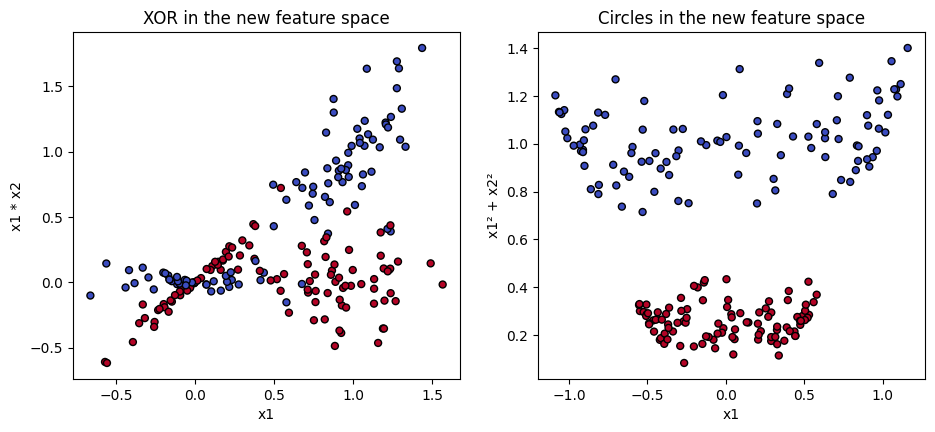

Circles become perfectly separable. XOR improves a lot, but the noisy points near the class borders still overlap, so it is not perfect.
Drawback: we had to design the feature by hand (this is what deep learning automates).


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_x2[:, 0], X_x2[:, 2], c=y_x, cmap="coolwarm", edgecolor="k", s=25)
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x1 * x2"); axes[0].set_title("XOR in the new feature space")
axes[1].scatter(X_c2[:, 0], X_c2[:, 2], c=y_c, cmap="coolwarm", edgecolor="k", s=25)
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x1² + x2²"); axes[1].set_title("Circles in the new feature space")
plt.show()
print("Circles become perfectly separable. XOR improves a lot, but the noisy points near the class borders still overlap, so it is not perfect.")
print("Drawback: we had to design the feature by hand (this is what deep learning automates).")

## 9. Fix 2: multi-layer networks (hidden layers + non-linear activations)

A network with a hidden layer **learns** useful new features by itself.

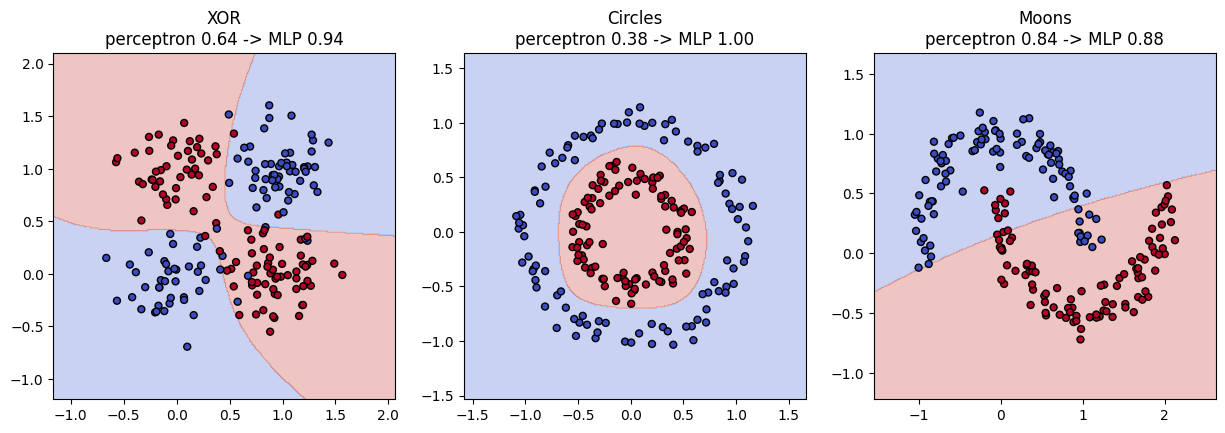

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, ["XOR", "Circles", "Moons"]):
    X_d, y_d = datasets[name]
    mlp = MLPClassifier(hidden_layer_sizes=(8, 8), activation="tanh", max_iter=3000, random_state=0).fit(X_d, y_d)
    perc_acc = (Perceptron(2).fit(X_d, y_d, epochs=200).predict(X_d) == y_d).mean()
    plot_boundary(ax, mlp.predict, X_d, y_d, f"{name}\nperceptron {perc_acc:.2f} -> MLP {mlp.score(X_d, y_d):.2f}")
plt.show()

## Summary of problems and fixes

| Problem | Why | Fix |
|---|---|---|
| Only linear boundaries | One hyperplane | Hidden layers, non-linear features |
| Never converges if not separable | Always some mistakes | Pocket algorithm, smooth loss |
| No unique / no max-margin solution | Stops at first separating line | SVM, regularization |
| Sensitive to scaling | Updates are proportional to feature values | Standardize inputs |
| Hard 0/1 output | Step activation | Sigmoid / softmax outputs |
| Not trainable by gradient descent through layers | Step has zero gradient | Smooth activations + backpropagation |
| Binary only | Single output | One-vs-rest, softmax layer |

## Practice exercises

1. Run the brute-force search for a NAND gate and a NOR gate. Can a single perceptron do them?
2. Try the moons dataset with extra features `x1²`, `x2²`, `x1·x2`. How close to 100% can a perceptron get?
3. Change `hidden_layer_sizes` for the MLP to `(1,)`, `(2,)`, `(4,)` on XOR. What is the smallest hidden layer that works?
4. Replace `activation="tanh"` with `activation="identity"` in the MLP. Why does XOR fail again?
5. Standardize the features in section 5 and compare updates for different learning rates.